<a href="https://colab.research.google.com/github/ananyavj/DeepLearning/blob/main/Question%201/B_Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/DeepLearning/datasets"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
BASE = "/content/drive/MyDrive/DeepLearning/datasets"
for root, dirs, files in os.walk(BASE):
    if root.count(os.sep) - BASE.count(os.sep) > 2:   # skip deep image folders
        continue
    for f in files[:10]:                               # first 10 files per folder
        print(os.path.join(root, f))

/content/drive/MyDrive/DeepLearning/datasets/FNN and CNN/Fashion MNIST/fashion-mnist_test.csv
/content/drive/MyDrive/DeepLearning/datasets/FNN and CNN/Fashion MNIST/fashion-mnist_train.csv
/content/drive/MyDrive/DeepLearning/datasets/FNN and CNN/HandWritten MNIST/mnist_train.csv
/content/drive/MyDrive/DeepLearning/datasets/FNN and CNN/HandWritten MNIST/mnist_test.csv
/content/drive/MyDrive/DeepLearning/datasets/FNN and CNN/Sign Language MNIST/Sign_Language_MNIST_Dataset_Information.txt
/content/drive/MyDrive/DeepLearning/datasets/Object Detection/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5
/content/drive/MyDrive/DeepLearning/datasets/CBOW/twitter_dataset.csv
/content/drive/MyDrive/DeepLearning/datasets/CBOW/IMDB Dataset.csv
/content/drive/MyDrive/DeepLearning/datasets/CBOW/document3.txt
/content/drive/MyDrive/DeepLearning/datasets/AutoEncoder/Sign Language MNIST/Sign_Language_MNIST_Dataset_Information.txt
/content/drive/MyDrive/DeepLearning/datasets/AutoEncoder/Sign Language MNIS

In [ ]:
import pandas as pd

train_df = pd.read_csv(f"{BASE}/FNN and CNN/Fashion MNIST/fashion-mnist_train.csv")
test_df = pd.read_csv(f"{BASE}/FNN and CNN/Fashion MNIST/fashion-mnist_test.csv")

print("Training data shape : ", train_df.shape)
print("Testing data shape : ", test_df.shape)
print(train_df.columns.tolist()[:10])
print(train_df.head(5))

Training data shape :  (60000, 785)
Testing data shape :  (10000, 785)
['label', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5', 'pixel6', 'pixel7', 'pixel8', 'pixel9']
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3       0  ...         3         0         0         0      

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

(60000, 784) (60000,)


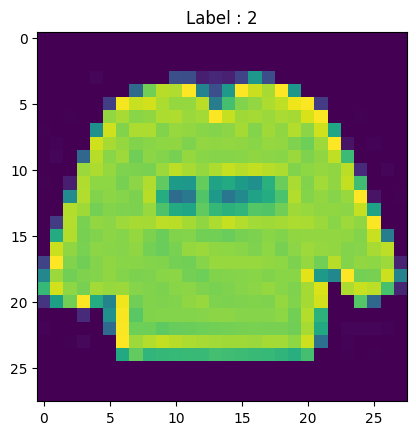

In [ ]:
X_train = train_df.drop("label", axis=1).values / 255.0
y_train = train_df["label"].values

X_test = test_df.drop("label", axis=1).values / 255.0
y_test = test_df["label"].values

print(X_train.shape, y_train.shape)

plt.imshow(X_train[0].reshape(28, 28))
plt.title(f"Label : {y_train[0]}")
plt.show()

In [ ]:
model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [ ]:
model.compile(
    optimizer = keras.optimizers.SGD(learning_rate = 0.1),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs = 11,
    batch_size = 32,
    validation_split = 0.1
)

Epoch 1/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.7975 - loss: 0.5534 - val_accuracy: 0.8092 - val_loss: 0.5214
Epoch 2/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8519 - loss: 0.4003 - val_accuracy: 0.8587 - val_loss: 0.3932
Epoch 3/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8655 - loss: 0.3660 - val_accuracy: 0.8515 - val_loss: 0.4158
Epoch 4/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8748 - loss: 0.3390 - val_accuracy: 0.8715 - val_loss: 0.3625
Epoch 5/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8806 - loss: 0.3218 - val_accuracy: 0.8755 - val_loss: 0.3463
Epoch 6/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8868 - loss: 0.3058 - val_accuracy: 0.8688 - val_loss: 0.3725
Epoch 7/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8906 - loss: 0.2934 - val_accuracy: 0.8708 - val_loss: 0.3420
Epoch 8/11
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8953 - loss: 0.2824 -

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test loss :  {test_loss}")
print(f"Test accuracy :  {test_accuracy}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8798 - loss: 0.3289
Test loss :  0.3288712501525879
Test accuracy :  0.879800021648407


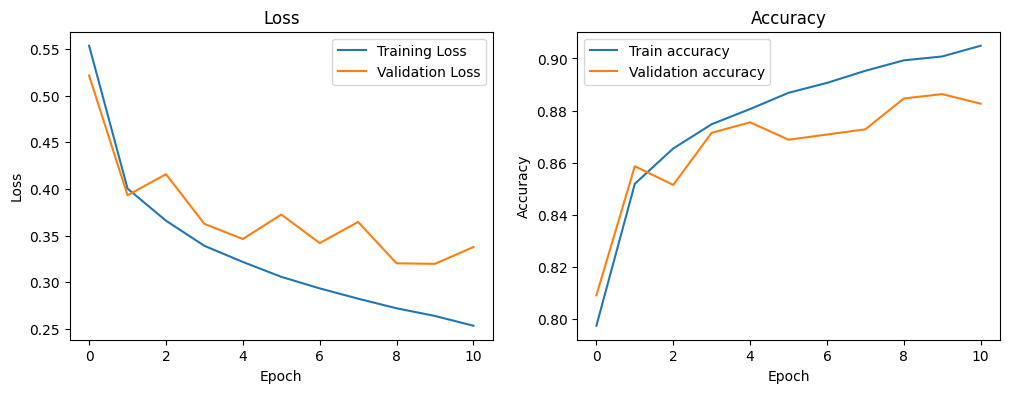

In [ ]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()


plt.show()
